In [6]:
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow_datasets as tfds
import numpy as np

import string
import math

In [9]:
!pip install importlib_resources

In [10]:
def plot_learning_curve(history):
    
    plt.figure()
    plt.plot(history.history['accuracy'], label='Training accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation accuracy')
    plt.title('accuracy Curves')
    plt.legend()
    plt.show()

    
    plt.figure()
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Loss Curves')
    plt.legend()
    plt.show()

In [11]:
(x_train, y_train), (x_test_full, y_test_full) = tfds.as_numpy(tfds.load(
    'emnist/byclass',
    split=['train', 'test'],
    batch_size=-1,
    as_supervised=True,
))

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dl Completed...: 0 url [00:00, ? url/s]
Dl Size...: 0 MiB [00:00, ? MiB/s]

Dl Completed...:   0%|                                 | 0/1 [00:00<?, ? url/s]
Dl Size...: 0 MiB [00:00, ? MiB/s]

Dl Size...:   0%|                                    | 0/535 [00:00<?, ? MiB/s]

Dl Size...:   0%|                            | 1/535 [00:00<03:47,  2.35 MiB/s]

Dl Size...:   0%|                            | 2/535 [00:00<02:14,  3.95 MiB/s]

Dl Size...:   1%|▏                           | 3/535 [00:00<01:43,  5.13 MiB/s]

Dl Size...:   1%|▏                           | 4/535 [00:00<01:29,  5.92 MiB/s]

Dl Size...:   1%|▎                           | 5/535 [00:00<01:19,  6.64 MiB/s]

Dl Size...:   1%|▎                           | 6/535 [00:00<01:12,  7.29 MiB/s]

Dl Size...:   1%|▎                           | 7/535 [00:00<01:06,  7.90 MiB/s]

Dl Size...:   1%|▍                           | 8/535 [00:00<01:03,  8.34 MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]
Dl Size...:   2%|▍           

Dataset emnist downloaded and prepared to /Users/imyairgonzalez/tensorflow_datasets/emnist/byclass/3.1.0. Subsequent calls will reuse this data.


In [12]:
X_test, X_val, y_test, y_val = train_test_split(
    x_test_full, y_test_full, test_size=0.50, random_state=42)

In [14]:
x_train.shape, X_test.shape

((697932, 28, 28, 1), (58161, 28, 28, 1))

In [15]:
X_train = x_train / 255.0
X_test = X_test / 255.0
X_val = X_val / 255.0

## Visualizacion de un elemento del conjunto de entrenamiento

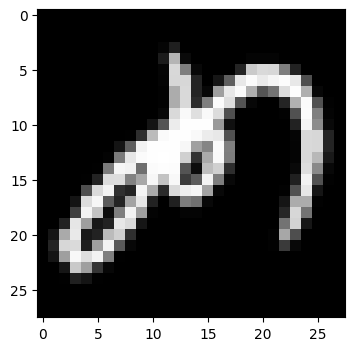

np.int64(14)

In [17]:
plt.figure(figsize=(4,4))
plt.imshow(X_train[2], cmap="gray", vmin=0, vmax=1.0)
plt.show()
y_train[2]

In [18]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],X_train.shape[2])),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 256, activation = "relu"),
    tf.keras.layers.Dense(units = 128, activation = "relu"),
    tf.keras.layers.Dense(units = 64, activation = "relu"),
    tf.keras.layers.Dense(units = 62, activation = "softmax")
])

model.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## Entrenamiento del Modelo

In [19]:
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size = 128,
    validation_data = (X_val,y_val)
)

Epoch 1/50
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 14s 2ms/step - accuracy: 0.7928 - loss: 0.6486 - val_accuracy: 0.8309 - val_loss: 0.4939
Epoch 2/50
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.8349 - loss: 0.4749 - val_accuracy: 0.8390 - val_loss: 0.4590
Epoch 3/50
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.8440 - loss: 0.4397 - val_accuracy: 0.8420 - val_loss: 0.4461
Epoch 4/50
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.8493 - loss: 0.4196 - val_accuracy: 0.8443 - val_loss: 0.4422
Epoch 5/50
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.8529 - loss: 0.4058 - val_accuracy: 0.8472 - val_loss: 0.4341
Epoch 6/50
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.8552 - loss: 0.3953 - val_accuracy: 0.8478 - val_loss: 0.4345
Epoch 7/50
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.8574 - loss: 0.3876 - val_accuracy: 0.8486 - val_loss: 0.4346
Epoch 8/50
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.8593 - loss: 0

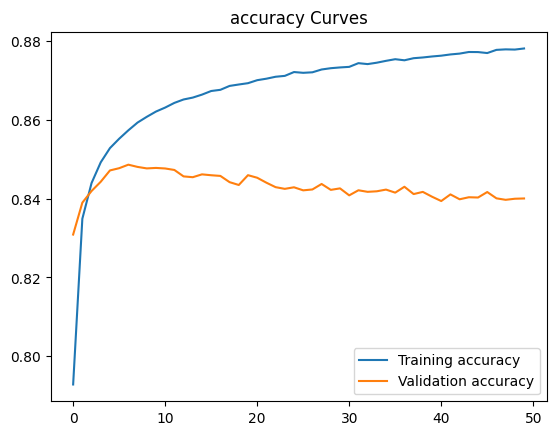

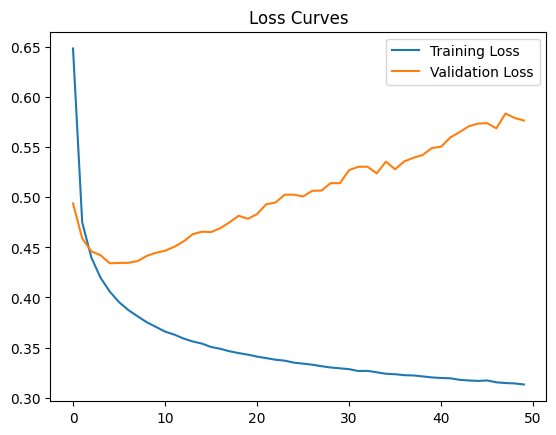

In [21]:
plot_learning_curve(history)

## Podemos Observar que el modelo eventualmente hizo overfiting

## Definamos un Nuevo Modelo usando las nuevas clases 

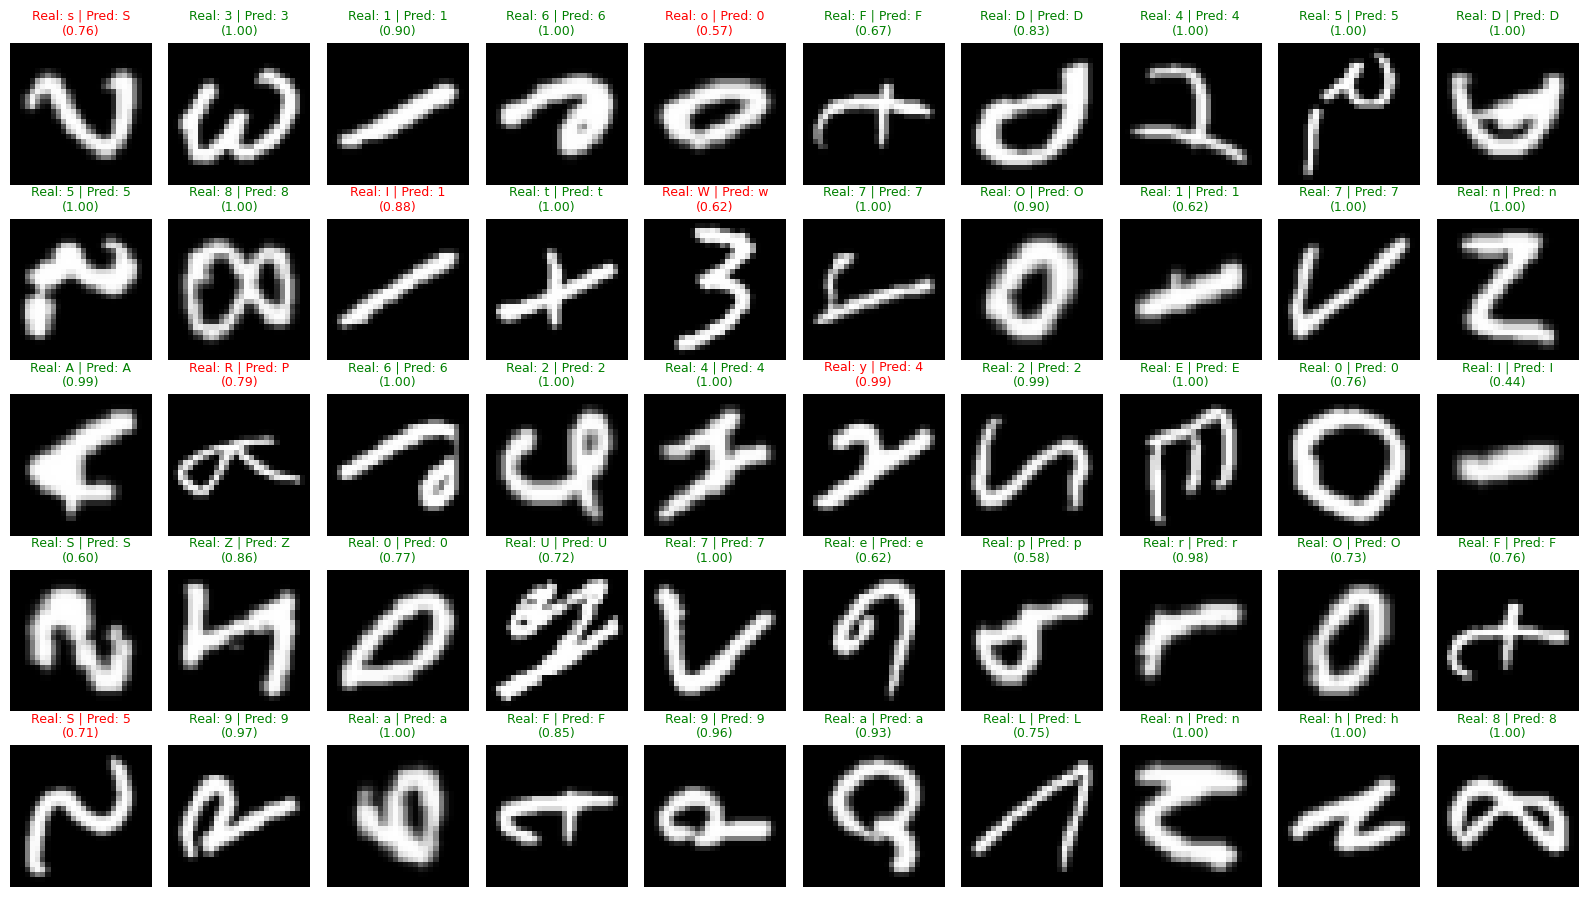

In [22]:
class_names = list(string.digits + string.ascii_uppercase + string.ascii_lowercase)


num_images = 50
original_images = X_test[:num_images]
original_labels = y_test[:num_images]


preds_original = model(original_images, training=False).numpy()


cols = 10
rows = math.ceil(num_images / cols)

fig, axes = plt.subplots(rows, cols, figsize=(16, 9))
axes = axes.flatten() 

for i in range(len(axes)):
    axes[i].axis('off')
    if i < num_images:
        axes[i].imshow(original_images[i], cmap='gray')
        
        true_idx = original_labels[i]
        pred_idx = np.argmax(preds_original[i])
        conf = preds_original[i][pred_idx]
        
    
        color = 'green' if true_idx == pred_idx else 'red'
        
        axes[i].set_title(
            f"Real: {class_names[true_idx]} | Pred: {class_names[pred_idx]}\n({conf:.2f})",
            color=color,
            fontsize=9
        )

plt.tight_layout()
plt.show()

In [23]:
model2d = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],X_train.shape[2])),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 256, activation = "relu"),
    tf.keras.layers.Dense(units = 128, activation = "relu"),
    tf.keras.layers.Dense(units = 64, activation = "relu"),
    tf.keras.layers.Dense(units = 2, activation = "linear", name = "rep_2d"),
    tf.keras.layers.Dense(units = 62, activation = "softmax")
])

model2d.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [24]:
model2d.fit(
    X_train,
    y_train,
    epochs=45,
    batch_size = 128,
    validation_data = (X_val,y_val)
)

Epoch 1/45
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 14s 2ms/step - accuracy: 0.5476 - loss: 1.6535 - val_accuracy: 0.6526 - val_loss: 1.2997
Epoch 2/45
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.6705 - loss: 1.2317 - val_accuracy: 0.6878 - val_loss: 1.1941
Epoch 3/45
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.7043 - loss: 1.1136 - val_accuracy: 0.7088 - val_loss: 1.1221
Epoch 4/45
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.7242 - loss: 1.0403 - val_accuracy: 0.7325 - val_loss: 1.0838
Epoch 5/45
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.7398 - loss: 0.9867 - val_accuracy: 0.7467 - val_loss: 1.0770
Epoch 6/45
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.7513 - loss: 0.9431 - val_accuracy: 0.7559 - val_loss: 1.0709
Epoch 7/45
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.7593 - loss: 0.9087 - val_accuracy: 0.7637 - val_loss: 1.0532
Epoch 8/45
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - accuracy: 0.7645 - loss: 0

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 856us/step


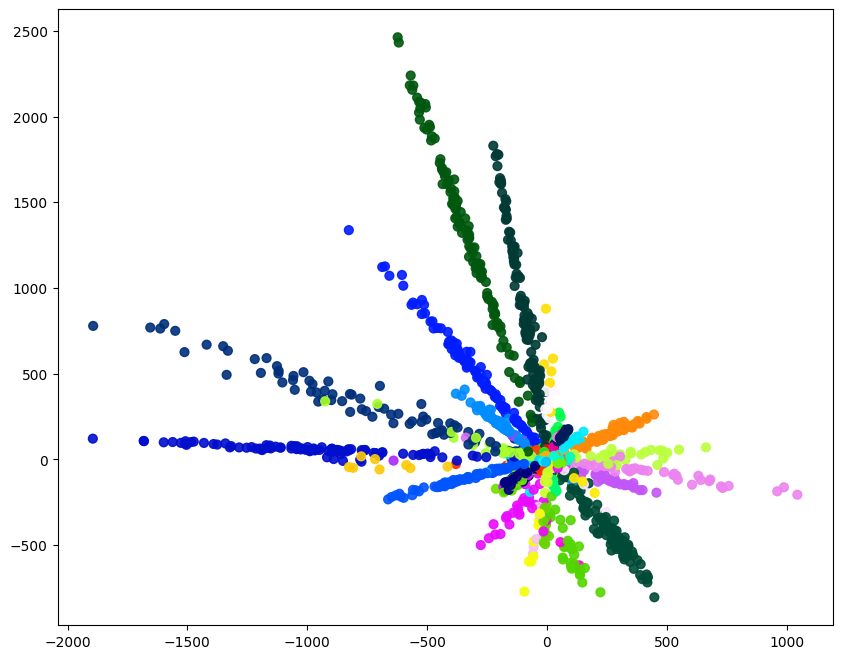

In [25]:
extractor = tf.keras.Model(
    inputs = model2d.inputs,
    outputs = model2d.get_layer("rep_2d").output
)

n = 2000
x_visual = X_val[:n]
y_visual = y_val[:n]

puntos2d = extractor.predict(x_visual)

plt.figure(figsize=(10,8))
scatter_plot = plt.scatter(
    puntos2d[:, 0],
    puntos2d[:, 1],
    c=y_visual,
    cmap="gist_ncar",
    s=40,
    alpha=0.9,
)

In [26]:
modelConvolucion = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],X_train.shape[2],1)),
    
    tf.keras.layers.Conv2D(32, (3, 3), padding = "same", activation = "relu"),
    tf.keras.layers.MaxPool2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), padding = "same", activation = "relu"),
    tf.keras.layers.MaxPool2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), padding = "same", activation = "relu"),
    tf.keras.layers.MaxPool2D((2, 2)),

    tf.keras.layers.Conv2D(256, (3, 3), padding = "same", activation = "relu"),
    tf.keras.layers.MaxPool2D((2, 2)),
    
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 128, activation = "relu"),
    tf.keras.layers.Dense(units = 64, activation = "relu"),
    tf.keras.layers.Dense(units = 62, activation = "softmax")
])

modelConvolucion.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [27]:
historyConvolucion = modelConvolucion.fit(
    X_train,
    y_train,
    epochs=9,
    batch_size = 128,
    validation_data = (X_val,y_val)
)

Epoch 1/9
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 136s 25ms/step - accuracy: 0.8264 - loss: 0.5139 - val_accuracy: 0.8583 - val_loss: 0.3908
Epoch 2/9
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 137s 25ms/step - accuracy: 0.8610 - loss: 0.3785 - val_accuracy: 0.8647 - val_loss: 0.3685
Epoch 3/9
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 133s 24ms/step - accuracy: 0.8679 - loss: 0.3539 - val_accuracy: 0.8674 - val_loss: 0.3615
Epoch 4/9
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 131s 24ms/step - accuracy: 0.8726 - loss: 0.3377 - val_accuracy: 0.8684 - val_loss: 0.3586
Epoch 5/9
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 131s 24ms/step - accuracy: 0.8760 - loss: 0.3250 - val_accuracy: 0.8678 - val_loss: 0.3626
Epoch 6/9
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 133s 24ms/step - accuracy: 0.8788 - loss: 0.3158 - val_accuracy: 0.8694 - val_loss: 0.3664
Epoch 7/9
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 137s 25ms/step - accuracy: 0.8810 - loss: 0.3082 - val_accuracy: 0.8677 - val_loss: 0.3726
Epoch 8/9
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 135s 25ms/step - accuracy: 0.8827 -

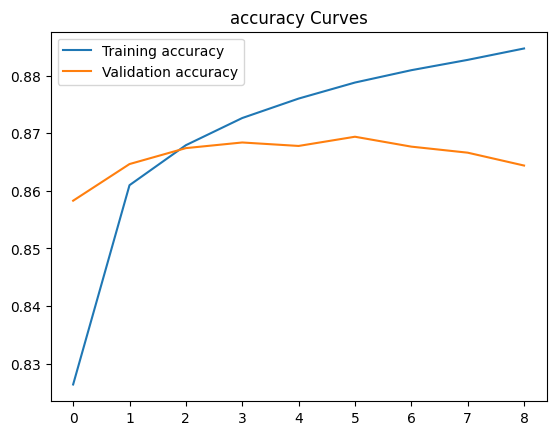

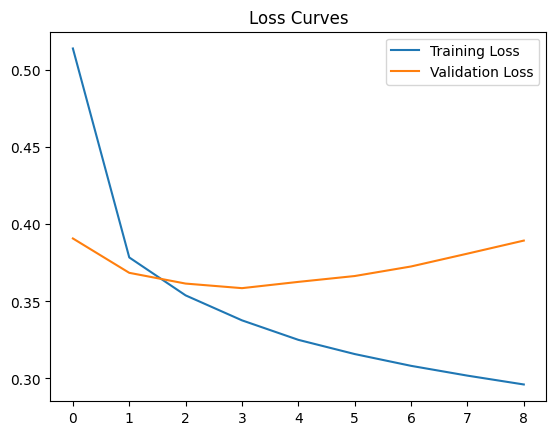

In [28]:
plot_learning_curve(historyConvolucion)

In [29]:
modelConvolucion3 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],X_train.shape[2],1)),
    
    tf.keras.layers.Conv2D(32, (3, 3), padding = "same", activation = "relu"),
    tf.keras.layers.MaxPool2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), padding = "same", activation = "relu"),
    tf.keras.layers.MaxPool2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), padding = "same", activation = "relu"),
    tf.keras.layers.MaxPool2D((2, 2)),
    
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 128, activation = "relu"),
    tf.keras.layers.Dense(units = 62, activation = "softmax")
])

modelConvolucion3.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [30]:
historyConvolucion3 = modelConvolucion3.fit(
    X_train,
    y_train,
    epochs=7,
    batch_size = 128,
    validation_data = (X_val,y_val)
)

Epoch 1/7
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 107s 20ms/step - accuracy: 0.8297 - loss: 0.5020 - val_accuracy: 0.8594 - val_loss: 0.3892
Epoch 2/7
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 103s 19ms/step - accuracy: 0.8618 - loss: 0.3753 - val_accuracy: 0.8651 - val_loss: 0.3663
Epoch 3/7
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 105s 19ms/step - accuracy: 0.8686 - loss: 0.3517 - val_accuracy: 0.8668 - val_loss: 0.3580
Epoch 4/7
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 103s 19ms/step - accuracy: 0.8731 - loss: 0.3363 - val_accuracy: 0.8680 - val_loss: 0.3554
Epoch 5/7
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 103s 19ms/step - accuracy: 0.8767 - loss: 0.3246 - val_accuracy: 0.8691 - val_loss: 0.3561
Epoch 6/7
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 102s 19ms/step - accuracy: 0.8799 - loss: 0.3147 - val_accuracy: 0.8681 - val_loss: 0.3622
Epoch 7/7
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 101s 19ms/step - accuracy: 0.8823 - loss: 0.3062 - val_accuracy: 0.8668 - val_loss: 0.3679


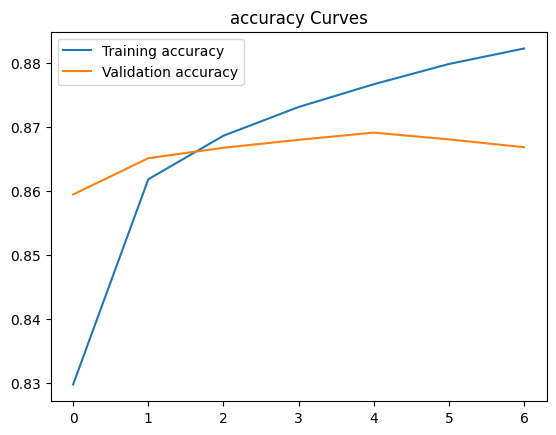

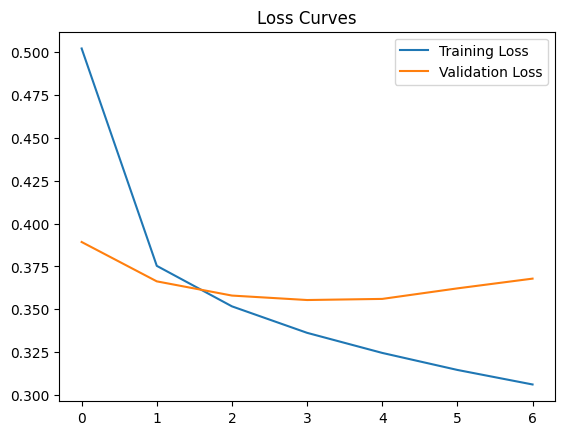

In [31]:
plot_learning_curve(historyConvolucion3)